# KQC QualityFactor — six λ/4 test resonators on one feedline (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' resonator Q test chip, `chips/quality_factor.py` (class `QualityFactor`,
default parameters; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/quality_factor.py`). Six `QuarterWaveCpwResonator`s
(5374 … 5589 µm, centre widths 5/10/20 µm with gaps 3/6/12 µm) hang below a feedline from launcher WN (PL-1-IN)
to EN (PL-1-OUT) of an SMA8 holder. Each is coupled through an interdigital or gap finger capacitor built into
the element; three start and end galvanically, three through airbridges. No qubits: the measurement is each
resonator's frequency and Q.

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (SMA8 launchers on its edges), Quantcore die frame, device ID "QFACTOR" |
| launchers | SMA8, only pads 8 (PL-1-IN) and 3 (PL-1-OUT), indent 800 µm | same two, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25: every f_r moves up (≈ +5 %) |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`) | **the original wins:** KQC's grid (`with_grid=True`), no PDK band |
| elements, positions, routes | — | kept: KQC's parameters; the resonator x positions follow KQC's own formula from the launcher ports (so they move with the launchers, as KQC's would: the six share a feedline span 160 µm shorter than KQC's, at a 973.3 µm pitch instead of 1000 µm) |
| placement | centred | centred (9 µm off in y, inside the 50 µm tolerance: no shift) |

**Kept:** the feedline path, including KQC's 1000 µm marker safety and the bend up to y = 7794.5 µm (centred
on the longest resonator); the resonator pitch from KQC's formula (1000 µm on KQC's launchers, 973.3 µm on the
deeper ones here); every `QuarterWaveCpwResonator` with its KQC
parameters (length, `max_res_len`, finger count and length, coupler type, `res_a`/`res_b`, beginning/termination
type, `n_ab` airbridges, probe-line stub 120 µm, transmission-line airbridges).

**Structure:** the feedline is seven CPW routes between the resonators' probe-line stubs, as in KQC; only the two
assigned SMA8 pads are drawn, as in KQC.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips corner rounding of the grid holes in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/qualityfactor")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack (resonator frequencies), the frame and pad rule, the airbridge
layers 300/301 and the cheese / 3/0 rules.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

10 × 10 mm with the SMA8 holder's pads 8 (PL-1-IN, west) and 3 (PL-1-OUT, east), the chip name "QFACTOR" (device
ID) and `with_grid=True`: KQC's whole-area ground grid, the original's cheese (no PDK band). The Quantcore frame
replaces KQC's ChipFrame.

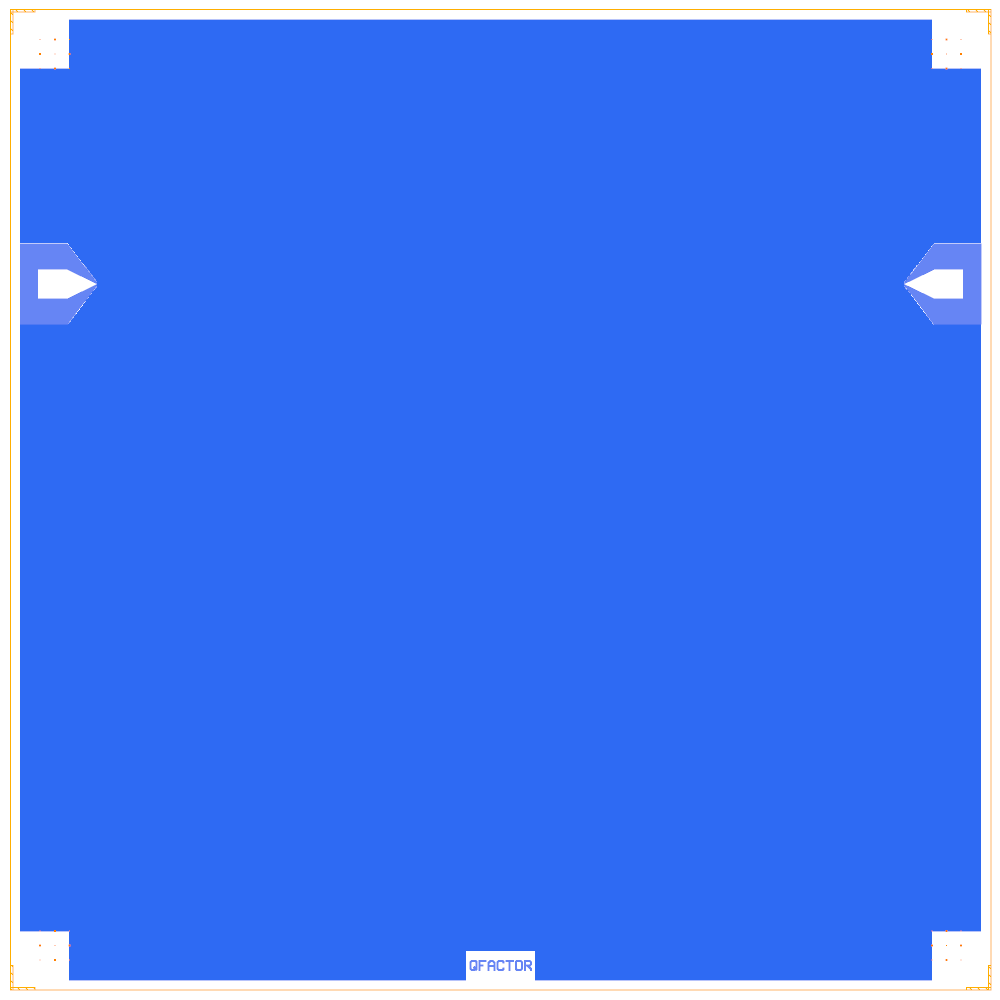

In [4]:
d = Designer("qualityfactor", box=(0, 0, 10000, 10000),
             launchers={"type": "SMA8", "assign": {8: "PL-1-IN", 3: "PL-1-OUT"}},
             chip={"name_chip": "QFACTOR", "with_grid": True}, live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

SMA8 launchers get `launcher_indent` = 100 + 300 + 300 + 180 = **880 µm** (KQC: 800): outer etch edge
`frame.pad_edge` (100 µm) from the die edge. KQC positions this chip's feedline and resonators from the launcher
refpoints, and so does the rebuild (`x_in`, `x_out` below come from the ports). The six resonators share the span
between the feedline corners, so the 80 µm deeper launchers shorten the pitch from 1000 to 973.3 µm (R0 and R5
sit 67 µm further in than in KQC).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.PL-1-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

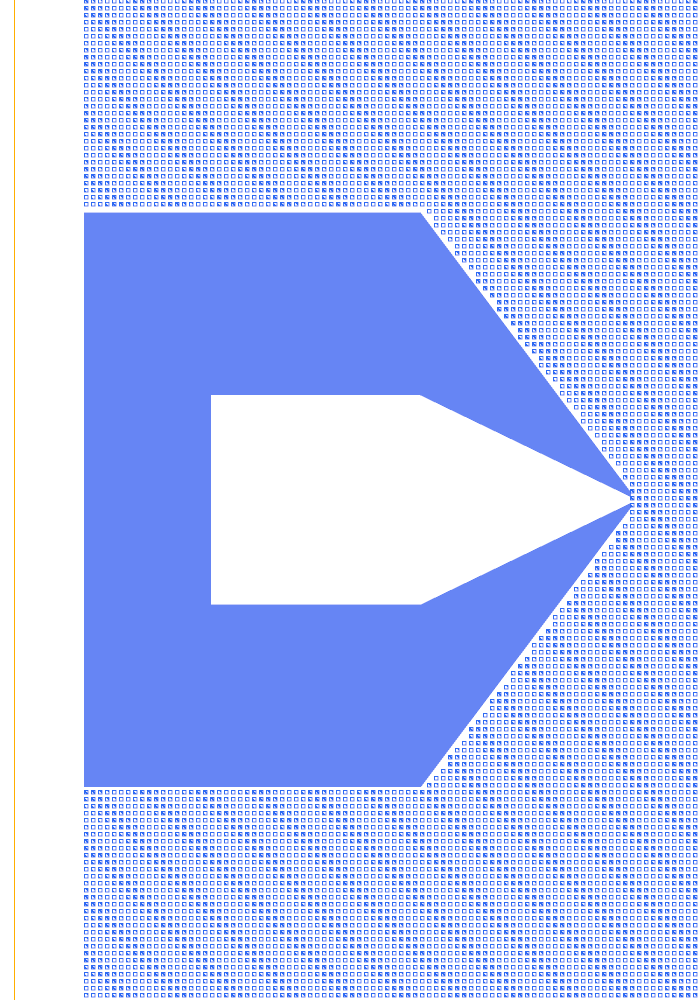

In [5]:
display(Markdown(pads_md(d)))
x_in, y_in = port_xy(d, "chip.PL-1-IN")
x_out, _ = port_xy(d, "chip.PL-1-OUT")
snap(d, STEPS / "2_launcher.png", box=(-20, y_in - 400, x_in + 100, y_in + 400), size=(700, 1000), width=300);

## 5 · Components

Six KQC `QuarterWaveCpwResonator`s, each a complete element: a 120 µm probe-line stub (ports `a`, `b`), the
coupling capacitor (`type_coupler` interdigital or gap, `n_fingers`, `l_fingers`) and the meandered λ/4 below it
(`resonator_length`, folded within `max_res_len`), with KQC's beginning / termination (`res_beg`, `res_term`:
galvanic or airbridge) and `n_ab` airbridges along it. They share the span between KQC's feedline
corners equally (KQC's formula: a 1000 µm pitch on KQC's launchers, 973.3 µm here), at the feedline height `y_top` that centres the longest resonator on the chip.

<QuarterWaveCpwResonator R0 ports=['a', 'b', 'resonator_b']>


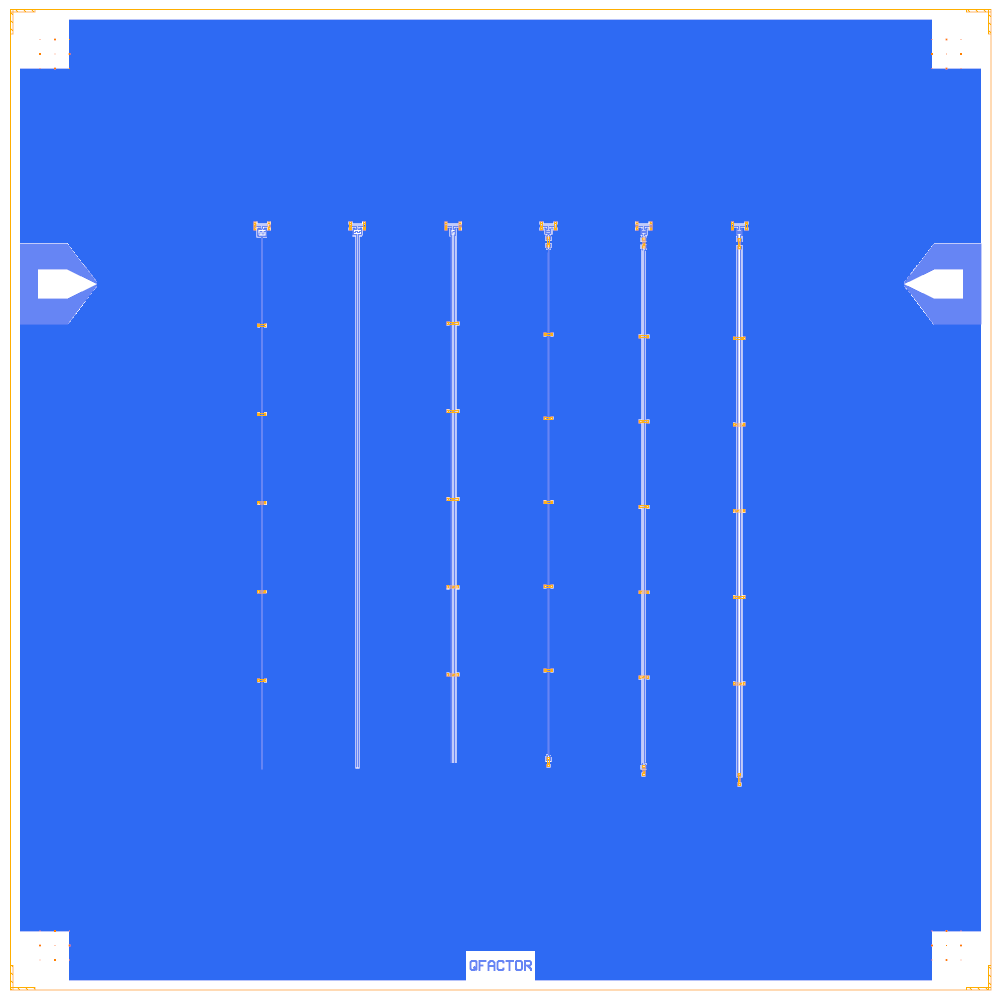

In [6]:
res_lengths = [5434, 5429, 5374, 5412, 5493, 5589]
n_fingers = [4, 4, 2, 4, 4, 4]
l_fingers = [23.1, 9.9, 14.1, 10, 21, 28]
coupler = ["interdigital", "interdigital", "interdigital", "gap", "gap", "gap"]
n_ab = [5, 0, 5, 5, 5, 5]
term = ["galvanic", "galvanic", "galvanic", "airbridge", "airbridge", "airbridge"]
res_a, res_b = [5, 10, 20, 5, 10, 20], [3, 6, 12, 3, 6, 12]

r, safety, bend = 100, 1000, 100                 # KQC: turn radius, marker_safety, feedline_bend_distance
y_top = (10000 + max(res_lengths)) / 2           # feedline height: the longest resonator is centred on the chip
x0, x1 = x_in + r + bend + safety, x_out - r - bend - safety
with d.batch():
    for i in range(6):
        d.add(f"R{i}", "QuarterWaveCpwResonator", at=(x0 + (i + 0.5) * (x1 - x0) / 6, y_top), probeline_length=120.0,
              resonator_length=res_lengths[i], max_res_len=max(res_lengths), res_beg=term[i], res_term=term[i],
              n_ab=n_ab[i], n_fingers=n_fingers[i], l_fingers=l_fingers[i], type_coupler=coupler[i],
              res_a=res_a[i], res_b=res_b[i], tl_airbridges=True)
print(d["R0"])
snap(d, STEPS / "3_components.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 6 · Routes

The feedline in seven CPW routes: PL-1-IN → up at KQC's marker-safety distance to `y_top` → R0's stub, stub to
stub, R5 → down → PL-1-OUT. The corner positions come from the launcher ports.

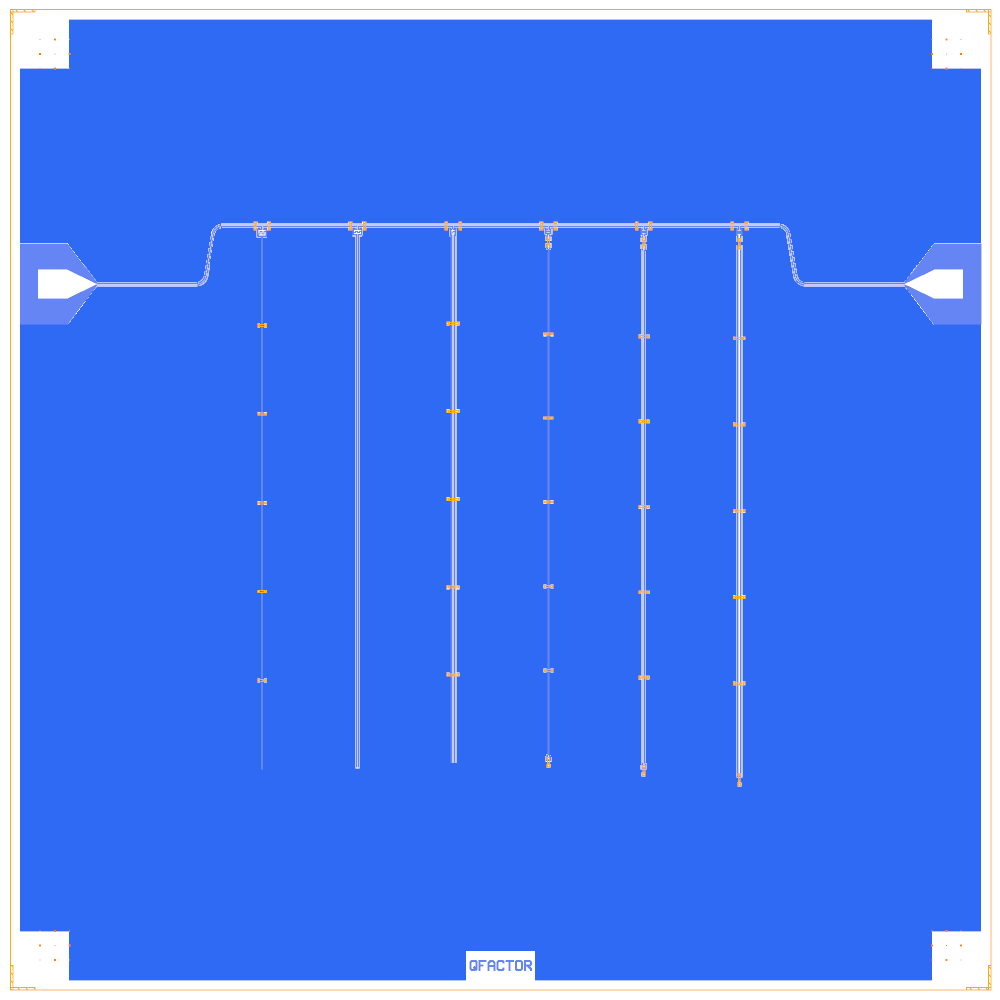

{'FL0': 2072.0, 'FL1': 853.3, 'FL2': 853.3, 'FL3': 853.3, 'FL4': 853.3, 'FL5': 853.3, 'FL6': 2072.0}


In [7]:
with d.batch():
    d.route("FL0", "chip.PL-1-IN", "R0.a", nodes=[(x_in + r + safety, y_in), (x0, y_top)])
    for i in range(1, 6):
        d.route(f"FL{i}", f"R{i - 1}.b", f"R{i}.a")
    d.route("FL6", "R5.b", "chip.PL-1-OUT", nodes=[(x1, y_top), (x_out - r - safety, y_in)])
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

**Sim groups, centring, save.** One sim group per resonator (200 µm margin; eigenmode and Q3D). `center_in_die`
finds the content 9 µm off in y, inside its 50 µm tolerance, so nothing moves; then `qualityfactor.json` is
saved.

In [8]:
for i in range(6):
    d.sim_group(f"R{i}", [f"R{i}"], margin_um=200, analyses=["eigenmode_epr", "q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "qualityfactor.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer qualityfactor: 6 instances, 7 routes, live=False> → examples\designs\kqc\qualityfactor.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** no junctions, so no `pdk_rn` / `pdk_fq`; the launchers follow the pad rule, so no `pad_edge`.

In [9]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 6 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 6 | R0.resonator_b is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, -9) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

Each `QuarterWaveCpwResonator` is one element with a probe-line node (ports `a`, `b` are one conductor), a λ/4
resonator node and the finger-capacitor coupling between them; the CPW routes join the probe-line nodes into one
feedline between the two 50 Ω launchers.

In [10]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**R0's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("R0."))))

**8 nodes · 14 branches · 0 controls · 6 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `R0.pl` | `R0.pl`, `R1.pl`, `R2.pl`, `R3.pl`, `R4.pl`, `R5.pl`, `chip.PL-1-IN`, `chip.PL-1-OUT` |
| `R0.res` | `R0.res` |
| `R1.res` | `R1.res` |
| `R2.res` | `R2.res` |
| `R3.res` | `R3.res` |
| `R4.res` | `R4.res` |
| `R5.res` | `R5.res` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Ck_R0` | C | `R0.pl` – `R0.res` | 10.8 fF |
| `Ck_R1` | C | `R0.pl` – `R1.res` | 7.53 fF |
| `Ck_R2` | C | `R0.pl` – `R2.res` | 4.12 fF |
| `Ck_R3` | C | `R0.pl` – `R3.res` | 3.11 fF |
| `Ck_R4` | C | `R0.pl` – `R4.res` | 2.51 fF |
| `Ck_R5` | C | `R0.pl` – `R5.res` | 2.32 fF |
| `Port_PL-1-IN` | R | `R0.pl` – `gnd` | 50 Ω |
| `Port_PL-1-OUT` | R | `R0.pl` – `gnd` | 50 Ω |
| `R0` | TLres | `R0.res` – `gnd` | lambda/4, 5434 µm, 5.795 GHz |
| `R1` | TLres | `R1.res` – `gnd` | lambda/4, 5429 µm, 5.804 GHz |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 5374 µm, 5.869 GHz |
| `R3` | TLres | `R3.res` – `gnd` | lambda/4, 5412 µm, 5.819 GHz |
| `R4` | TLres | `R4.res` – `gnd` | lambda/4, 5493 µm, 5.736 GHz |
| `R5` | TLres | `R5.res` – `gnd` | lambda/4, 5589 µm, 5.643 GHz |

**Unconnected ports:** `R0.resonator_b`, `R1.resonator_b`, `R2.resonator_b`, `R3.resonator_b`, `R4.resonator_b`, `R5.resonator_b`

**R0's ports → circuit nodes:**

| port | node |
|---|---|
| `R0.a` | `R0.pl` |
| `R0.b` | `R0.pl` |
| `R0.resonator_b` | `R0.res` |

## 9 · LOM simulation

Six linear resonator modes: frequency and external κ through the two 50 Ω launchers (no junctions, so no
anharmonicity and nothing for QuTiP beyond the harmonic levels). The loaded Q_ext = f_r / κ is what this chip
measures (together with the internal Q, which a LOM does not predict).

In [11]:
res = simulate_lom(lb, d.design, max_modes=2)
display(Markdown(modes_md(res)))
display(Markdown("| mode | f_r (GHz) | κ (MHz) | Q_ext = f_r / κ |\n|---|---|---|---|\n" + "\n".join(
    f"| {m.label} | {m.f_GHz:.4f} | {m.kappa_MHz:.3g} | {m.f_GHz * 1e3 / m.kappa_MHz:,.0f} |"
    for m in res.modes if m.kappa_MHz)))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| R5 | resonator | 5.6268 | 0.0652 | 0.0 | R5 1.00 |
| R0 | resonator | 5.7146 | 1.49 | 0.0 | R0 1.00 |
| R4 | resonator | 5.7181 | 0.116 | 0.0 | R4 1.00 |
| R1 | resonator | 5.7486 | 0.74 | 0.0 | R1 1.00 |
| R3 | resonator | 5.7949 | 0.133 | 0.0 | R3 1.00 |
| R2 | resonator | 5.8379 | 0.23 | 0.0 | R2 1.00 |

| mode | f_r (GHz) | κ (MHz) | Q_ext = f_r / κ |
|---|---|---|---|
| R5 | 5.6268 | 0.0652 | 86,253 |
| R0 | 5.7146 | 1.49 | 3,848 |
| R4 | 5.7181 | 0.116 | 49,370 |
| R1 | 5.7486 | 0.74 | 7,769 |
| R3 | 5.7949 | 0.133 | 43,557 |
| R2 | 5.8379 | 0.23 | 25,423 |

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one **eigenmode** job per resonator (cut out with a 200 µm margin): the two feedline routes leaving the box
end in 50 Ω lumped ports, so the solve gives f_r and the external Q, which is what this chip measures. (The
groups also list `q3d_cmatrix`, but in a C-matrix the shorted λ/4 is part of ground, so that job would only have
the feedline net; it is not exported here.)

In [12]:
jobs = send_fem_jobs(DESIGN, analyses=["eigenmode_epr"], run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

6 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| R0 · eigenmode_epr | `build/jobs/qualityfactor_R0_eigenmode_epr` | 1 · edge_lumped · `FL0`<br>2 · edge_lumped · `FL1` | `FL0`, `FL1` |
| R1 · eigenmode_epr | `build/jobs/qualityfactor_R1_eigenmode_epr` | 1 · edge_lumped · `FL1`<br>2 · edge_lumped · `FL2` | `FL1`, `FL2` |
| R2 · eigenmode_epr | `build/jobs/qualityfactor_R2_eigenmode_epr` | 1 · edge_lumped · `FL2`<br>2 · edge_lumped · `FL3` | `FL2`, `FL3` |
| R3 · eigenmode_epr | `build/jobs/qualityfactor_R3_eigenmode_epr` | 1 · edge_lumped · `FL3`<br>2 · edge_lumped · `FL4` | `FL3`, `FL4`, `R3.res`, `R3.pl` |
| R4 · eigenmode_epr | `build/jobs/qualityfactor_R4_eigenmode_epr` | 1 · edge_lumped · `FL4`<br>2 · edge_lumped · `FL5` | `FL4`, `FL5`, `R4.res`, `R4.pl` |
| R5 · eigenmode_epr | `build/jobs/qualityfactor_R5_eigenmode_epr` | 1 · edge_lumped · `FL5`<br>2 · edge_lumped · `FL6` | `FL5`, `FL6`, `R5.res`, `R5.pl` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [13]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for R0 · eigenmode_epr, R1 · eigenmode_epr, R2 · eigenmode_epr, R3 · eigenmode_epr, R4 · eigenmode_epr, R5 · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The coupling capacitor sets Q_ext. Lengthen R0's interdigital fingers from 23.1 to 40 µm: the coupling
capacitance grows, κ of R0 rises (Q_ext falls, roughly with the square of the capacitance) and f_r drops
slightly; the other five resonators do not change. The change is made on a copy (`design_copy`), so
`qualityfactor.json` keeps KQC's 23.1 µm.

In [14]:
def modes_delta_md(r0, r1):                      # before/after of every normal mode (QuCat)
    m0, m1 = {m.label: m for m in r0.modes}, {m.label: m for m in r1.modes}
    rows = ["| mode | f before (GHz) | f after (GHz) | Δf (MHz) | κ before (MHz) | κ after (MHz) |",
            "|---|---|---|---|---|---|"]
    for k in m0:
        if k in m1:
            a, b = m0[k], m1[k]
            rows.append(f"| {k} | {a.f_GHz:.4f} | {b.f_GHz:.4f} | {1e3 * (b.f_GHz - a.f_GHz):+.1f} | "
                        f"{a.kappa_MHz:.3g} | {b.kappa_MHz:.3g} |")
    return "\n".join(rows)


d2 = design_copy(DESIGN)
d2["R0"].set(l_fingers=40)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=2)
display(Markdown("**R0 coupler fingers: 23.1 → 40 µm**\n\n" + modes_delta_md(res, res2)))

**R0 coupler fingers: 23.1 → 40 µm**

| mode | f before (GHz) | f after (GHz) | Δf (MHz) | κ before (MHz) | κ after (MHz) |
|---|---|---|---|---|---|
| R5 | 5.6268 | 5.6268 | +0.0 | 0.0652 | 0.0652 |
| R0 | 5.7146 | 5.6851 | -29.5 | 1.49 | 2.84 |
| R4 | 5.7181 | 5.7180 | -0.1 | 0.116 | 0.0828 |
| R1 | 5.7486 | 5.7486 | +0.0 | 0.74 | 0.738 |
| R3 | 5.7949 | 5.7949 | -0.0 | 0.133 | 0.134 |
| R2 | 5.8379 | 5.8379 | +0.0 | 0.23 | 0.23 |

## 13 · Build and export

**The design file.** `qualityfactor.json` is the whole design: `qcc build examples/designs/kqc/qualityfactor.json`
rebuilds `build/qualityfactor.oas` + sidecar.

**The fab mask.** `export_fab` writes the PDK fab layers: base etch 1/0 with the cheese (source `build`: KQC's
grid), the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every grid hole), the airbridges on 300/0 (pads) and 301/0 (bridges) — KQC's resonator and
feedline bridges — and the frame (100/0, 1000/0, 1001/0). Corner rounding is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/qualityfactor.json` writes the complete file.

**Simulation export options.** No cheese in simulation exports; airbridges are dropped unless `airbridges=True`
— here that matters, since R3–R5 are airbridge-terminated and every line carries bridges. `setup.geometry`
reports what was left out.

In [15]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "R3", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 919652 |
| 3/0 | M3 | 872116 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 300/0 | AIRBRIDGE_PADS | 86 |
| 301/0 | AIRBRIDGE_BRIDGE | 43 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 919641 holes on the mask.

→ `build/qualityfactor_fab.oas`

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 27, 'airbridges': 'dropped'}
airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

Full chip; the couplers of R0 (interdigital, galvanic ends) and R3 (gap coupler, airbridge-terminated); the die
frame's south-west corner; R0's coupler in the **fab view** (the mask from step 13: 1/0 with KQC's grid holes,
the 3/0 keep-out, the airbridge layers); and KQC's own `QualityFactor` built stand-alone. (The layout snapshots
show KQC's ground grid, as one tone at full-chip scale, and draw the chip boundary 100/0 as an outline; the fab
view shows the grid holes on 1/0 and on 3/0.)

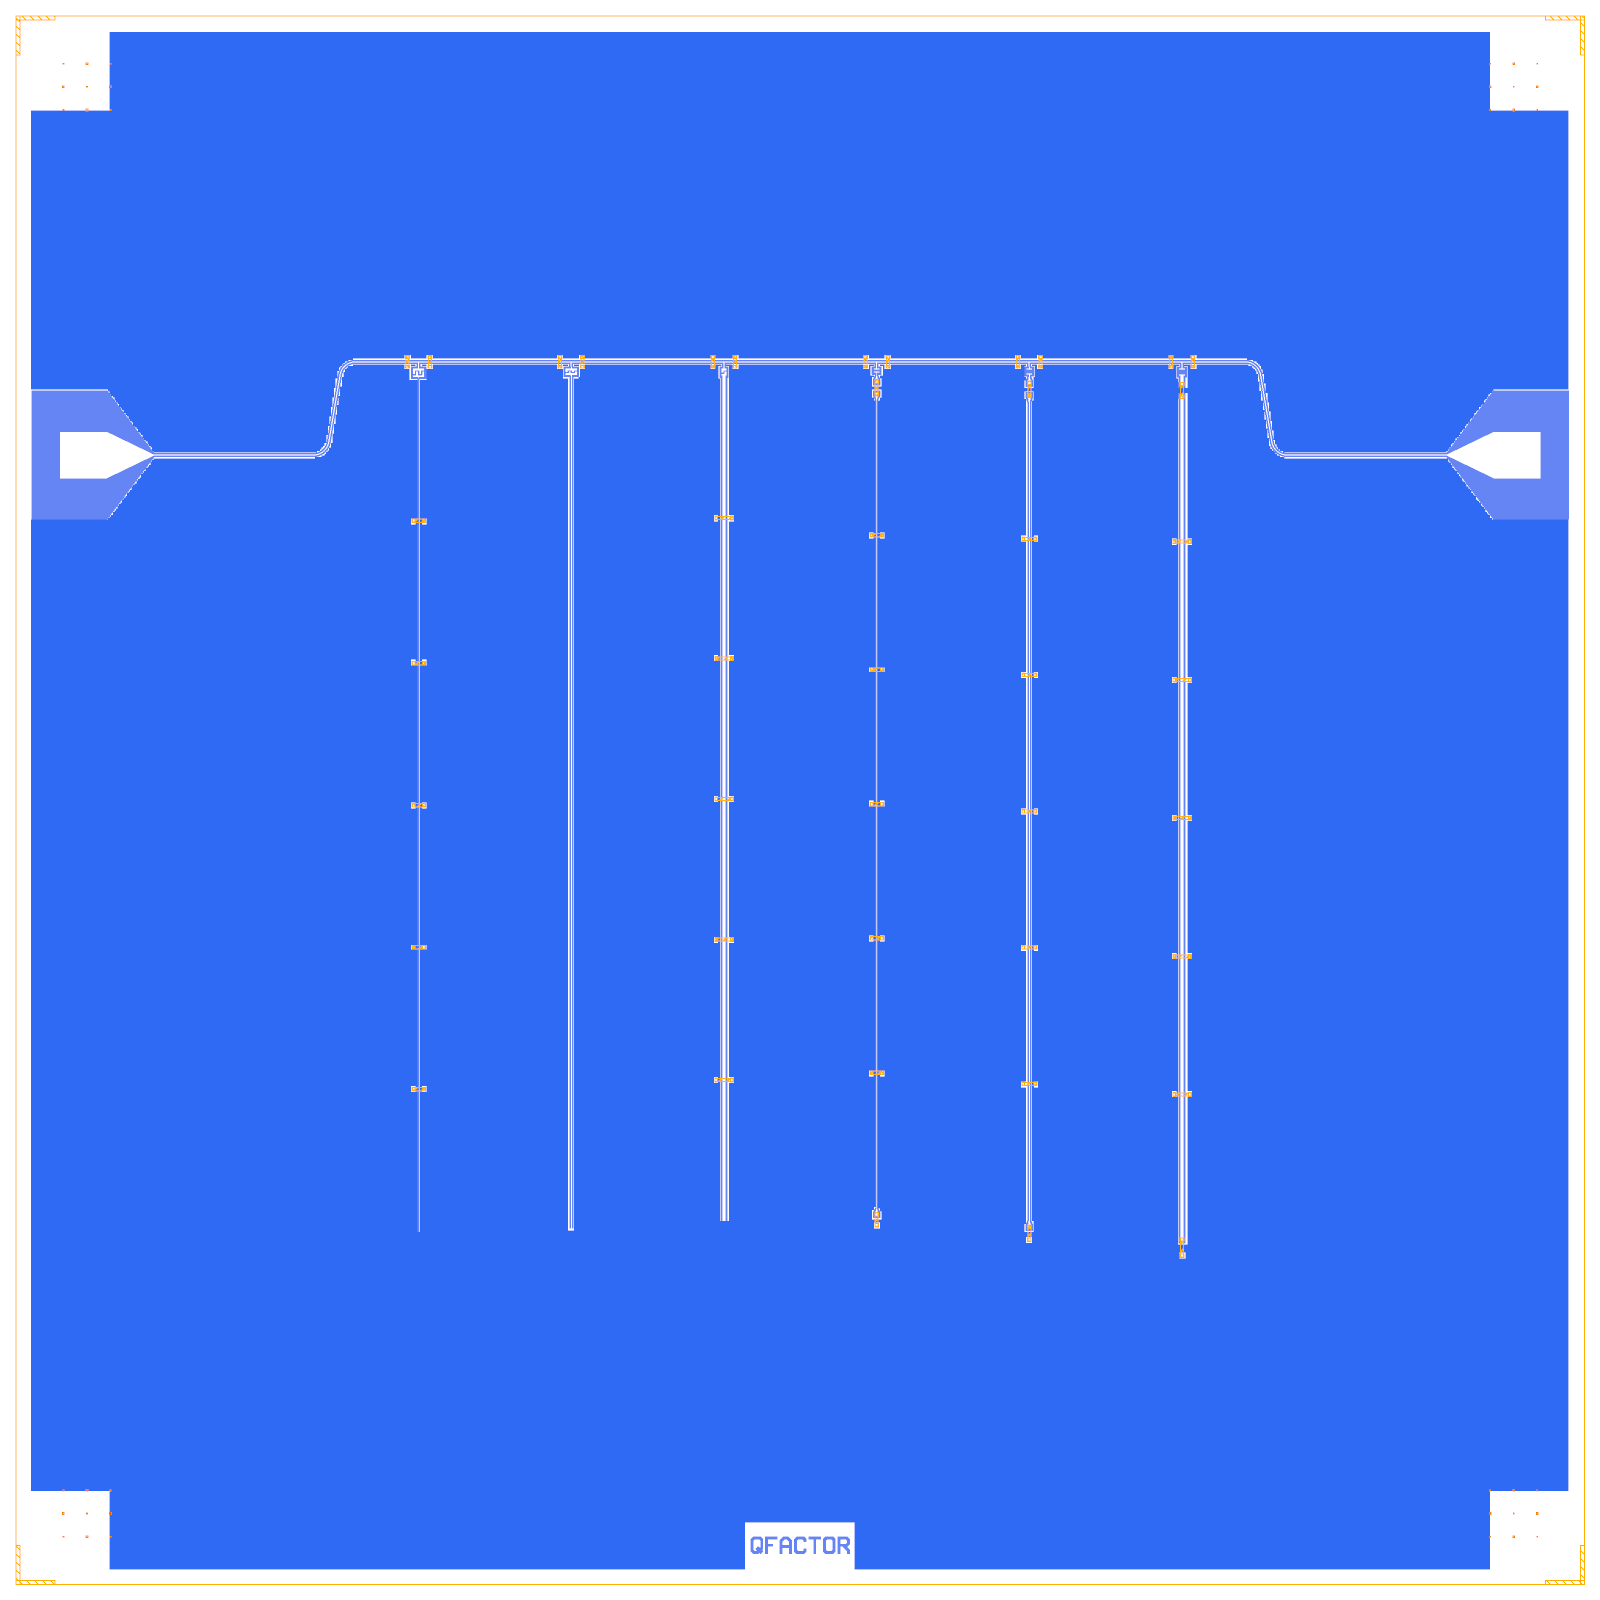

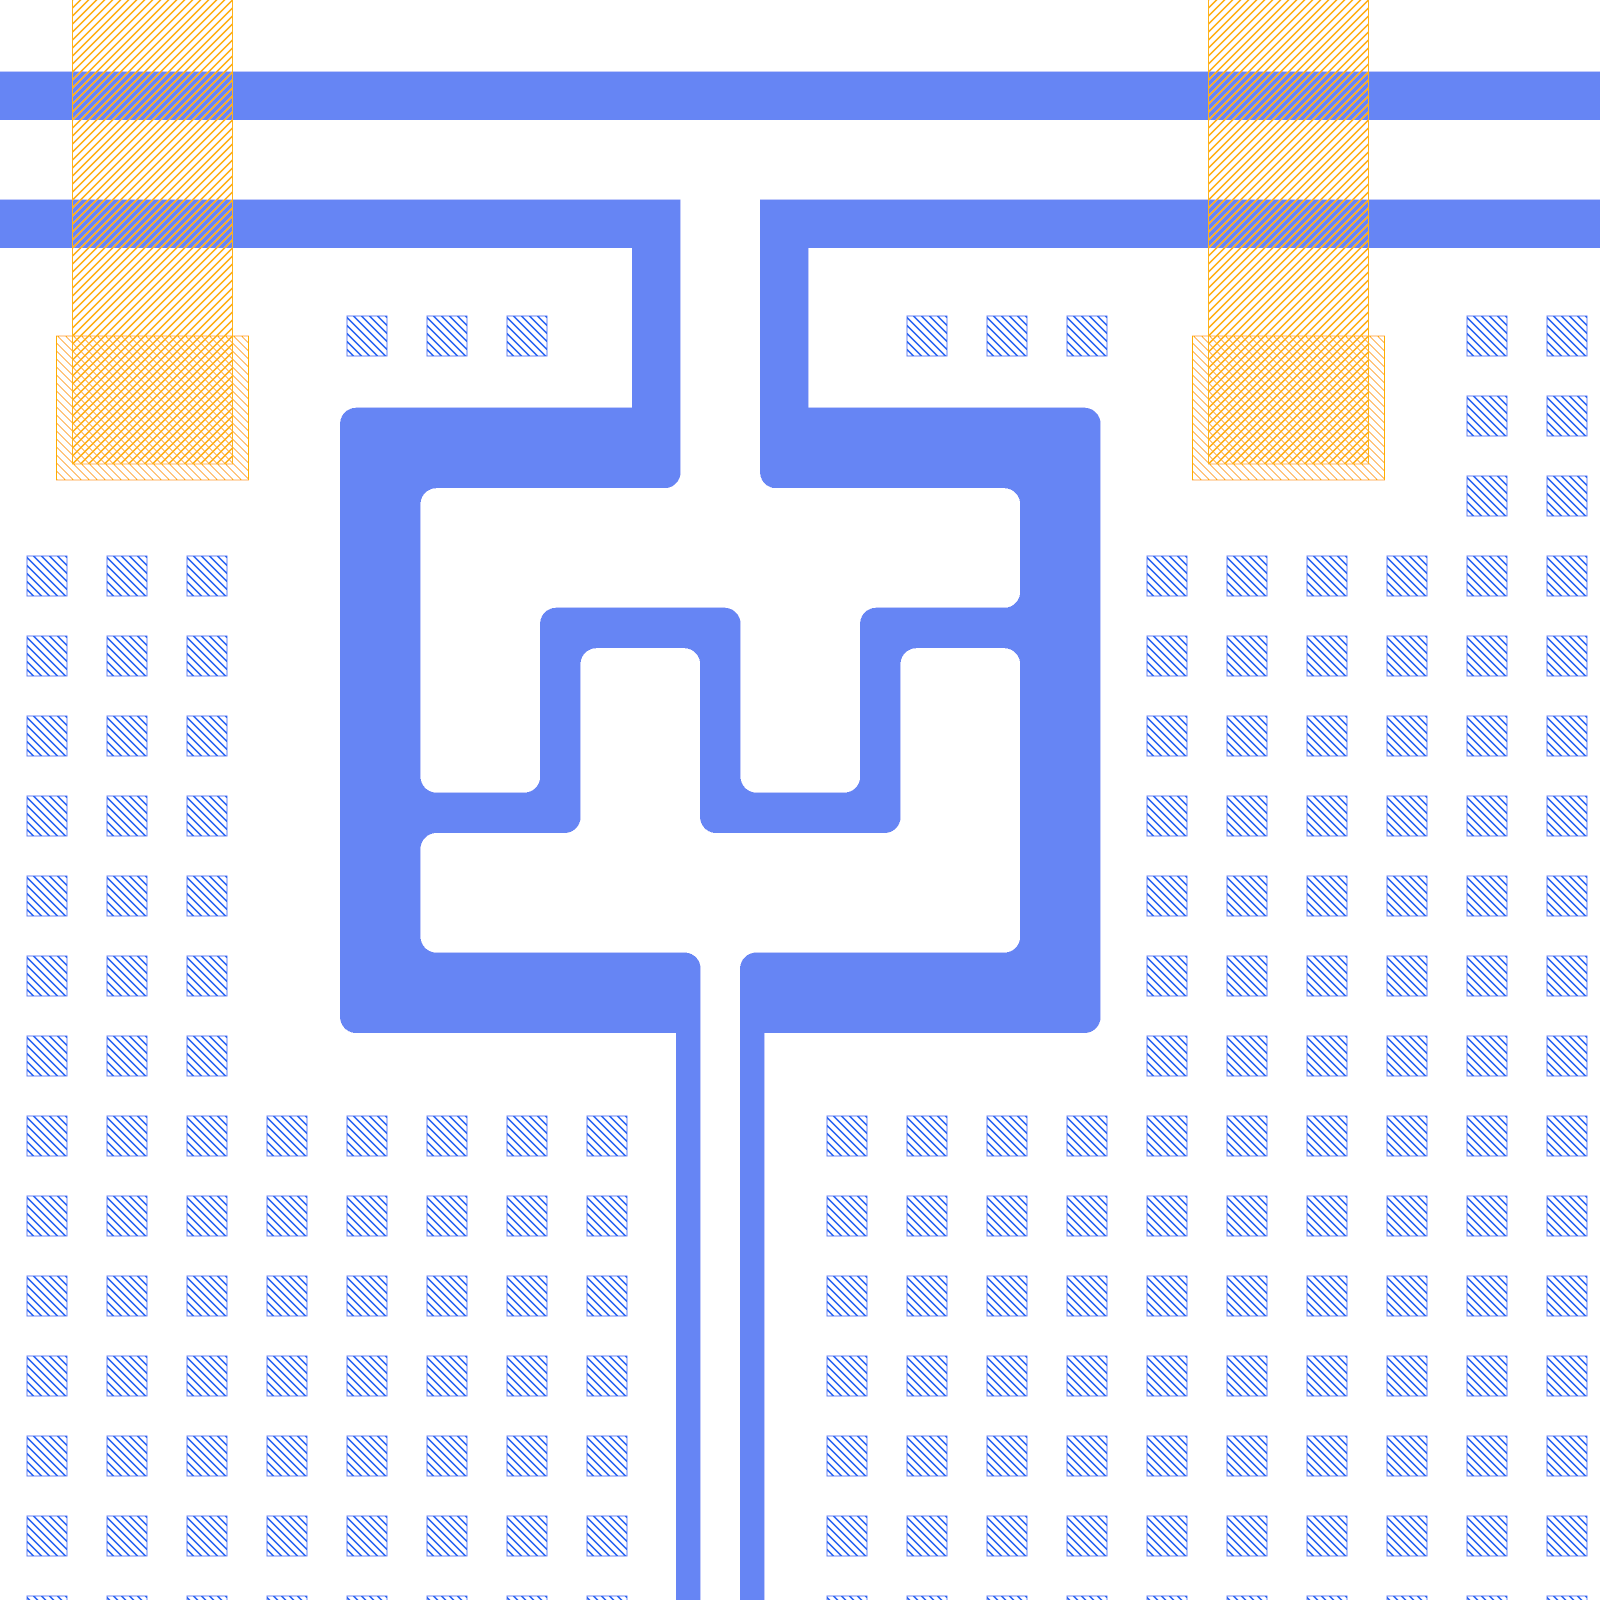

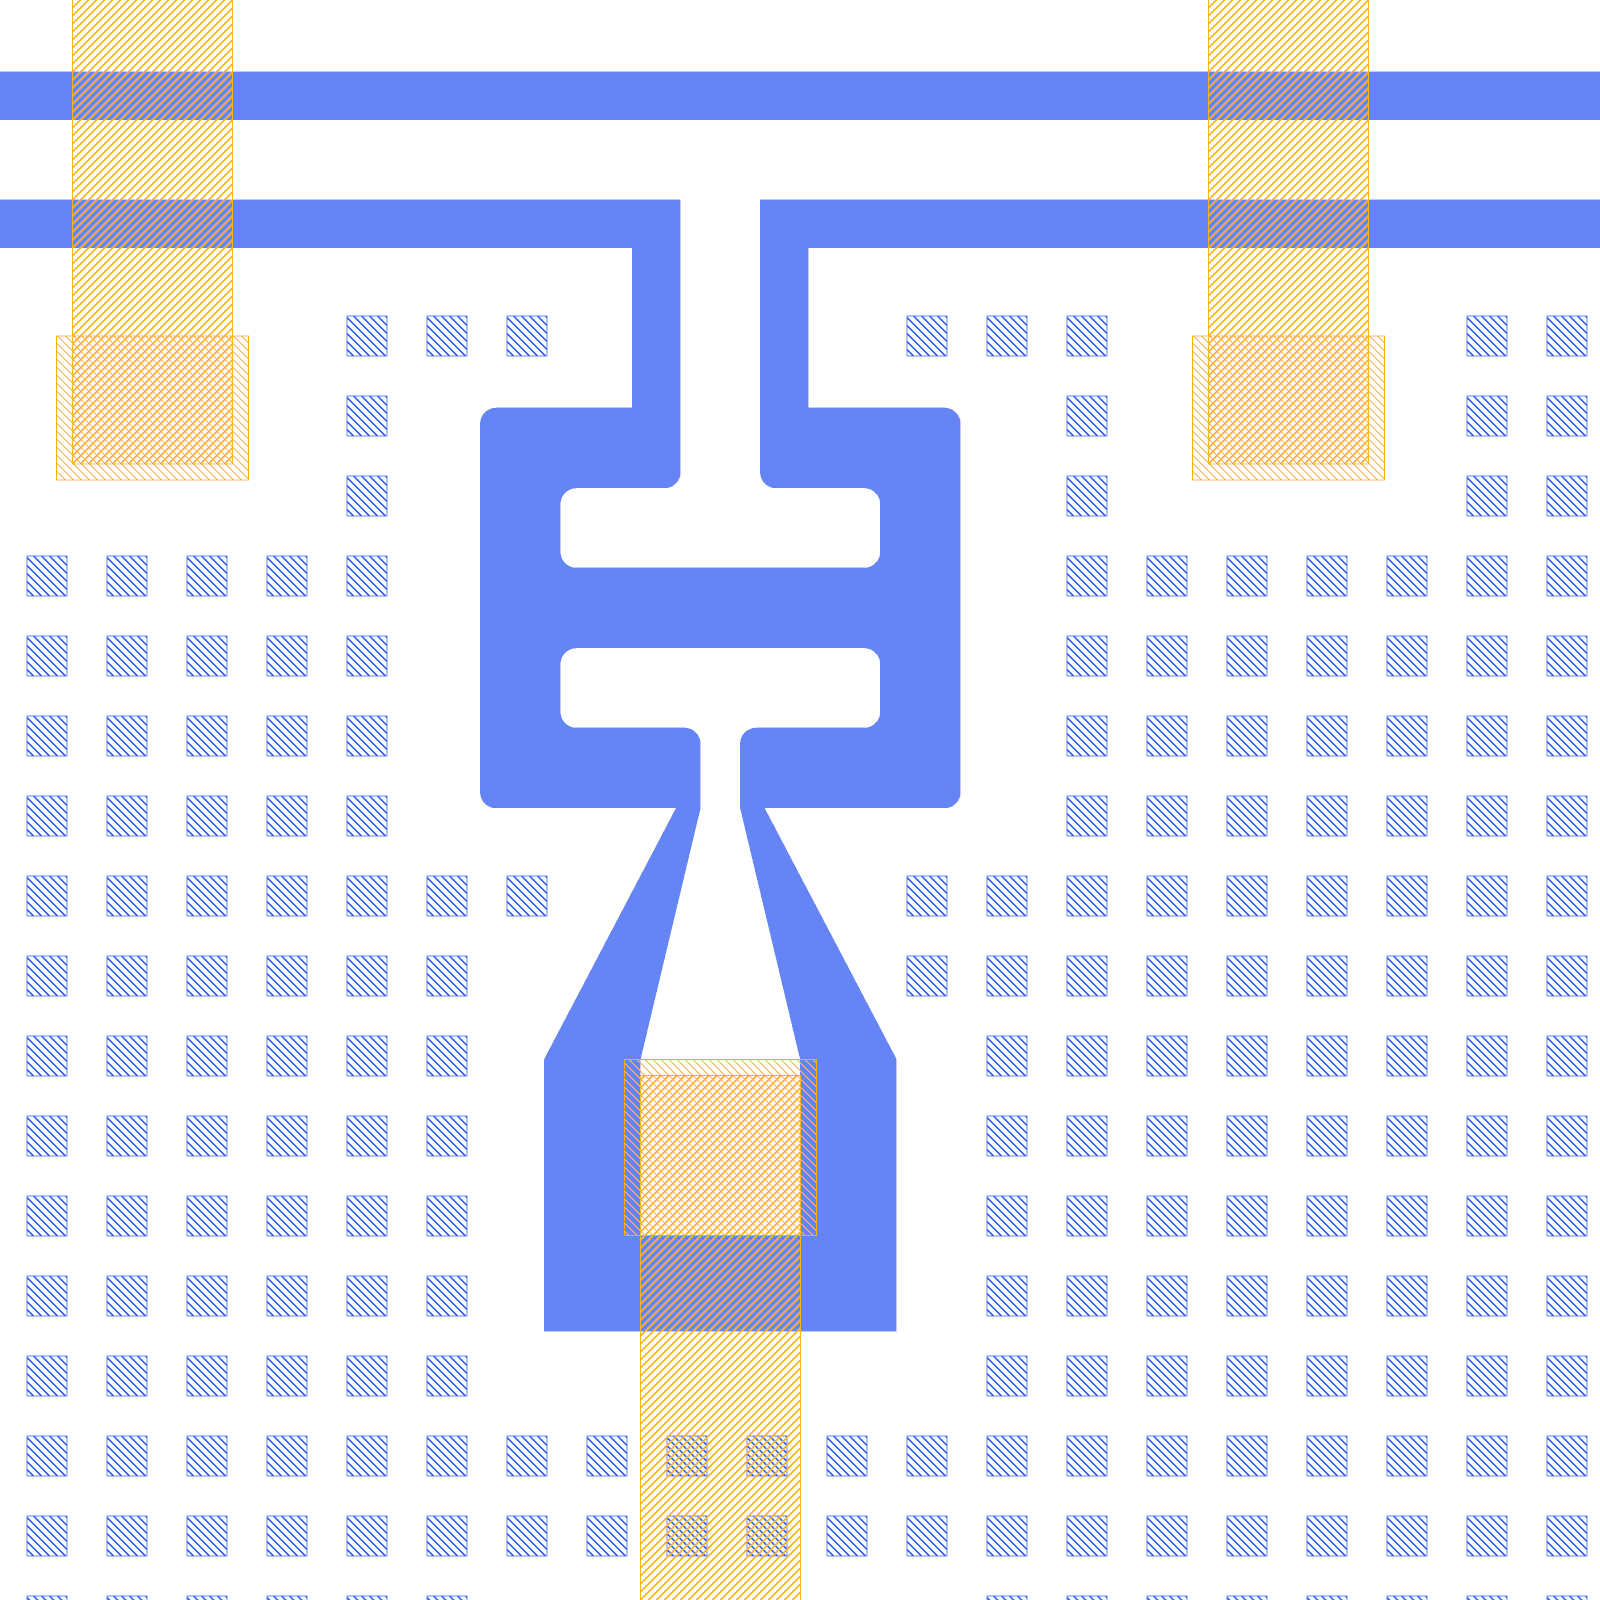

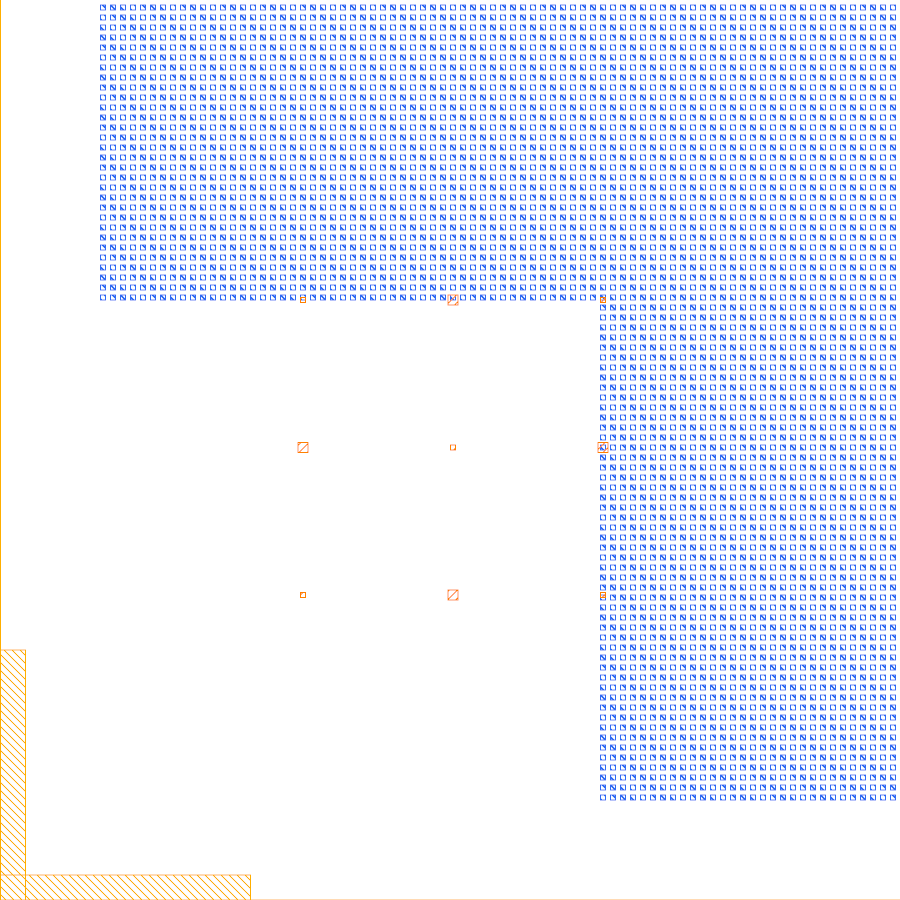

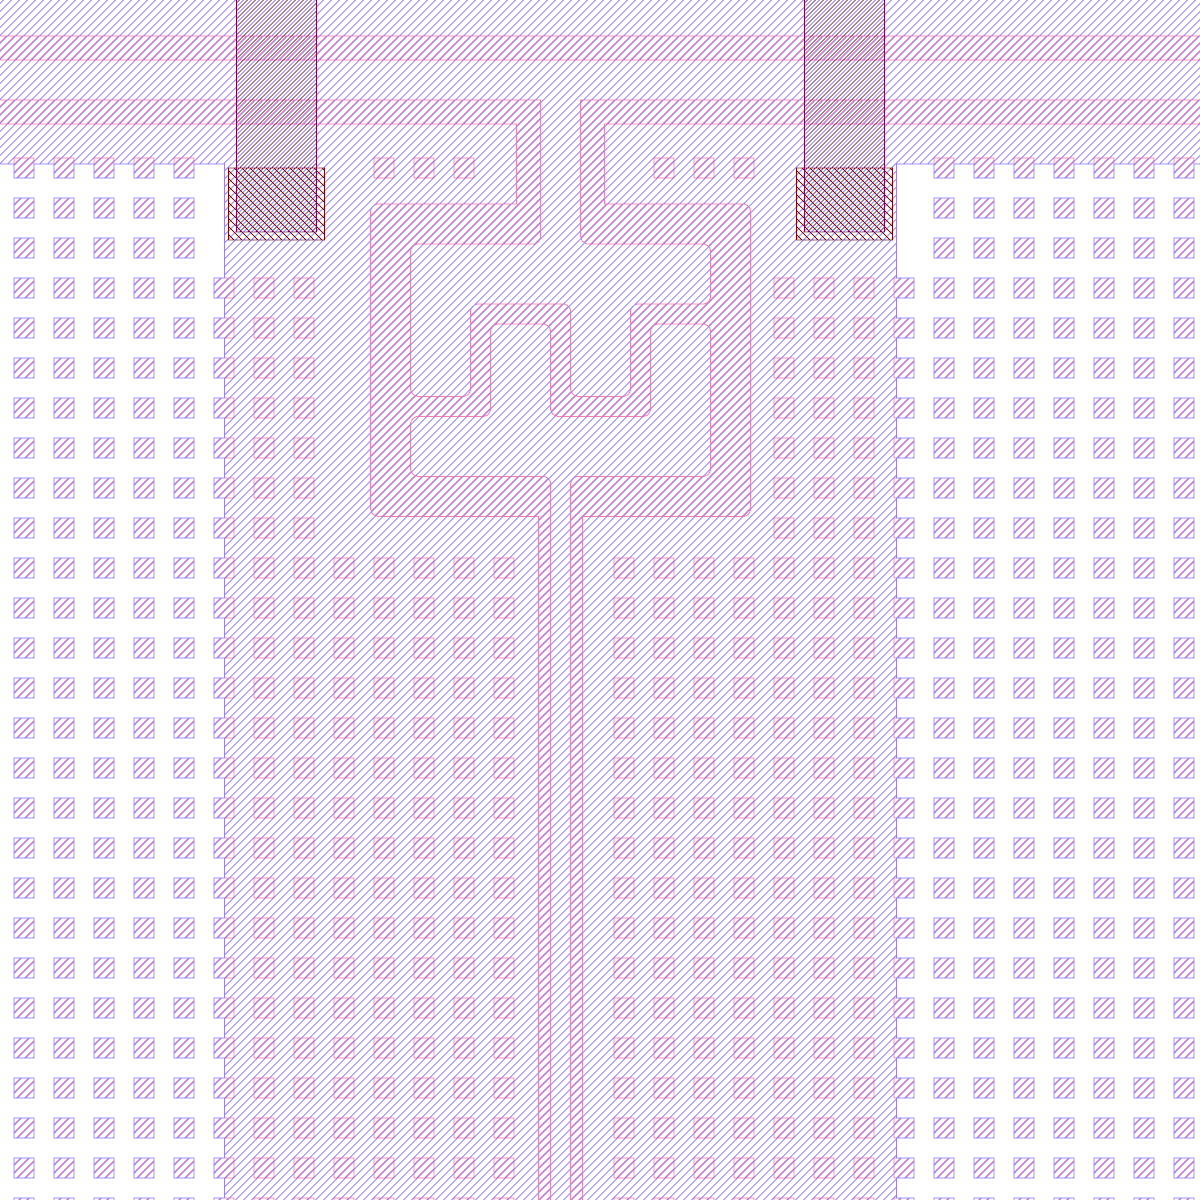

In [16]:
show_snapshot(d, OUT / "qualityfactor.png", box=(-100, -100, 10100, 10100))   # chip only
for i in (0, 3):
    x, y = port_xy(d, f"R{i}.a")
    show_snapshot(d, OUT / f"qualityfactor_coupler_r{i}.png", box=(x + 10, y - 180, x + 130, y + 20), width=360)
show_snapshot(d, OUT / "qualityfactor_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
x, y = port_xy(d, "R0.a")
snap_file(Path("build") / "qualityfactor_fab.oas", OUT / "qualityfactor_fab_r0.png", box=(x - 80, y - 280, x + 220, y + 20),
          size=(1200, 1200), width=420);

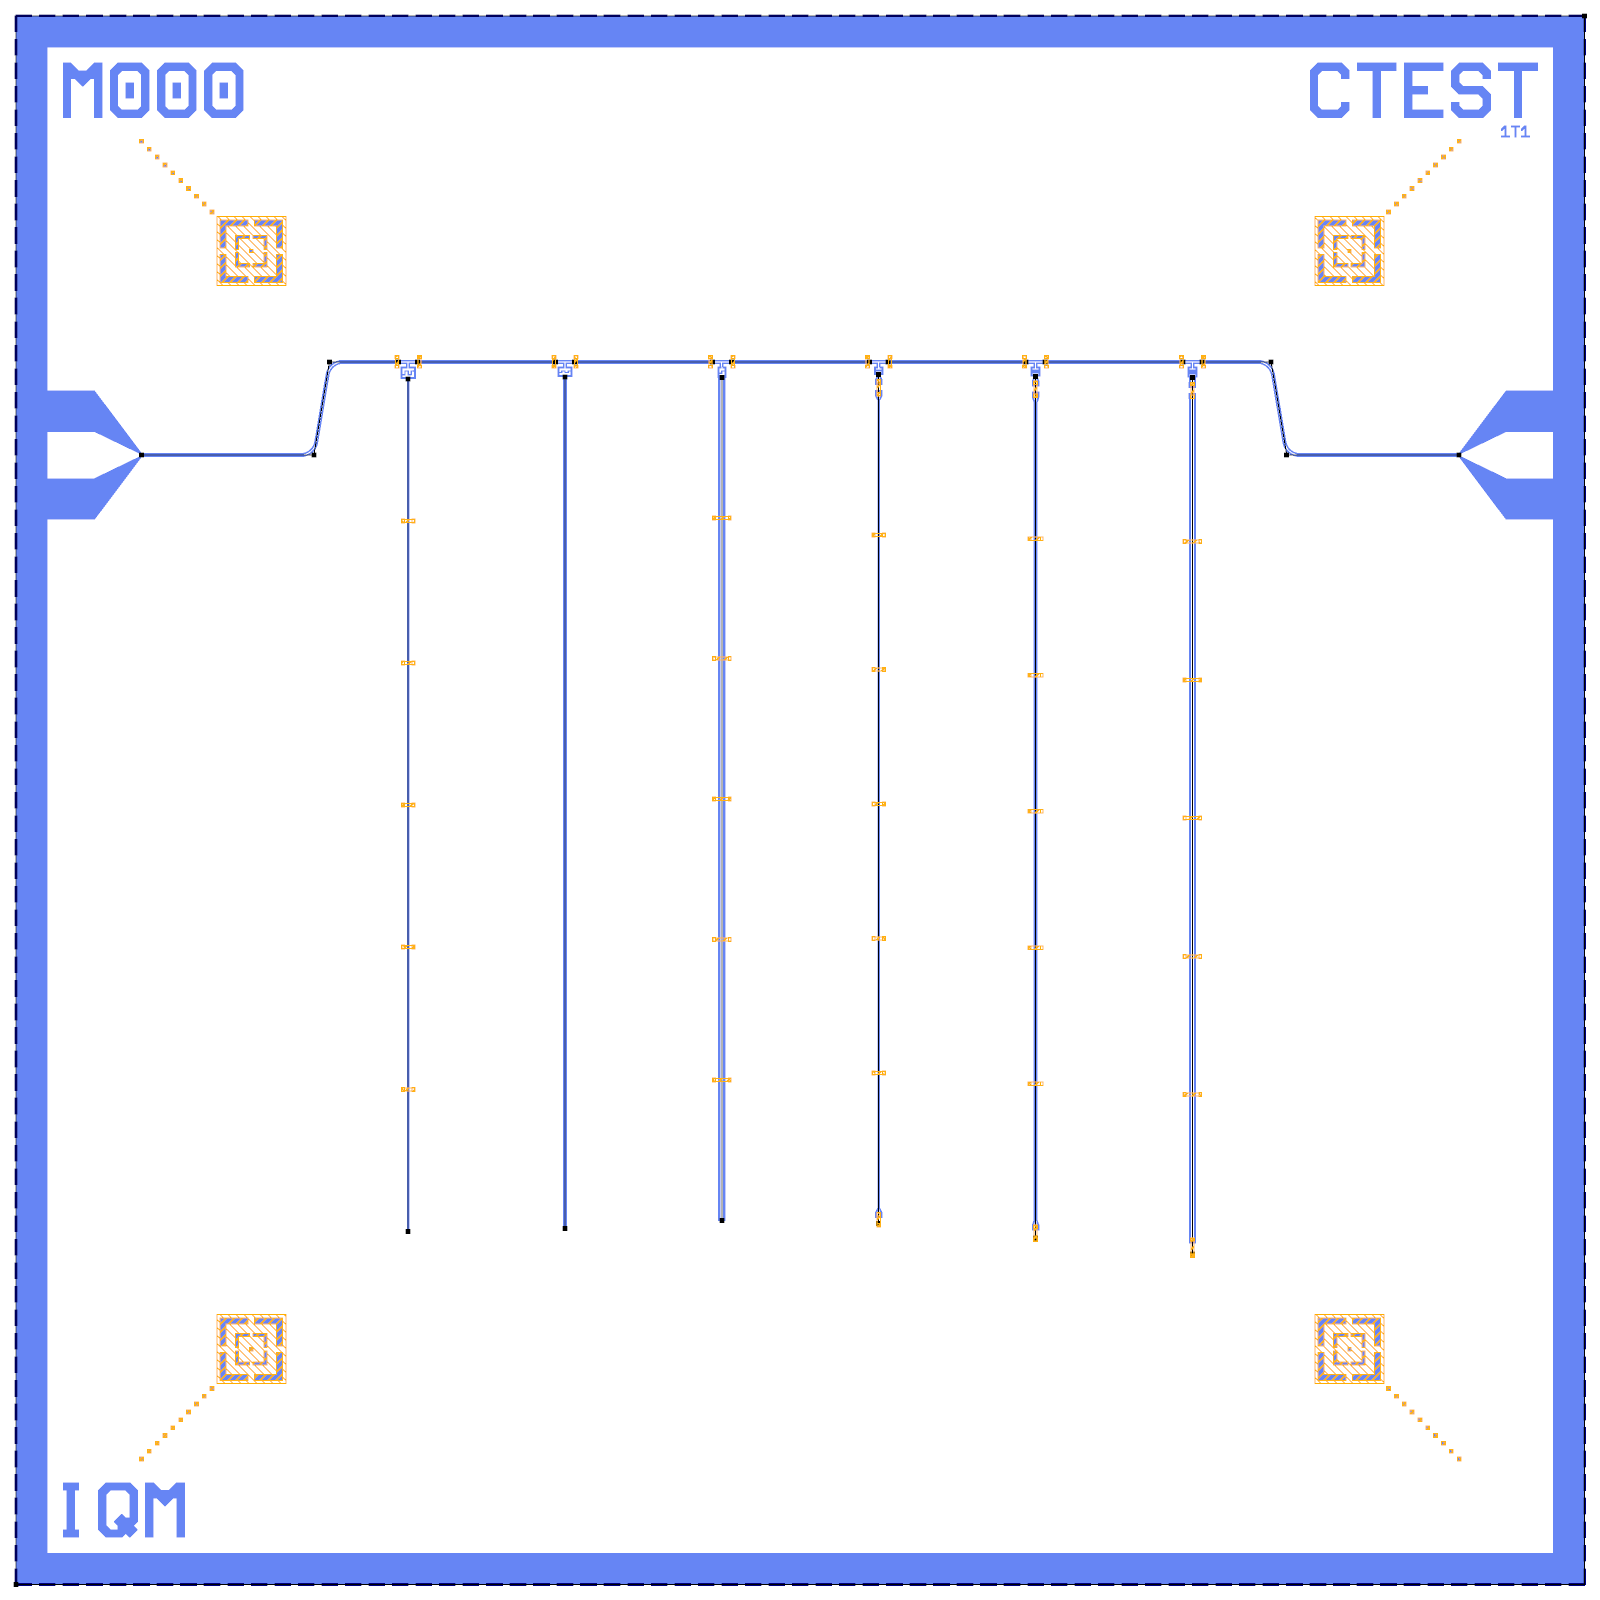

In [17]:
from kqcircuits.chips.quality_factor import QualityFactor
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_qualityfactor")
top.insert(pya.DCellInstArray(QualityFactor.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "qualityfactor_kqc_original.oas"))
snap_file(Path("build") / "qualityfactor_kqc_original.oas", OUT / "qualityfactor_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | the six `QuarterWaveCpwResonator`s with KQC's parameters, the feedline path and pitch (from the launcher refpoints, as KQC), the two SMA8 pads, the airbridges; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame; launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`), so the resonator pitch is 973.3 µm instead of 1000 µm (R0 and R5 67 µm further in); sapphire (f_r ≈ 5 % higher than on silicon) |
| **PDK design warnings** | none |
| **FEM** | 6 eigenmode jobs exported (`build/jobs/qualityfactor_R*_eigenmode_epr`), not solved here |